In [1]:
from pathlib import Path
import os

print("Current directory:", os.getcwd())

for folder in ["data", "models", "reports"]:
    path = Path(folder)
    print(f"\n{folder}/")
    if path.exists():
        for file in path.iterdir():
            print("  ", file.name)
    else:
        print("  Folder not found")

Current directory: C:\Users\vikra\Desktop\Project

data/
   customer_intelligence.db
   raw

models/
   .ipynb_checkpoints
   customer_churn_config.joblib
   customer_churn_optimized_pipeline.joblib
   customer_churn_pipeline.joblib
   customer_churn_schema.joblib

reports/
   best_model_test_metrics.csv
   contract_churn.csv
   customer_risk_segments.csv
   customer_segment_analysis.csv
   dashboard_contract_summary.csv
   dashboard_customer_data.csv
   dashboard_risk_summary.csv
   deployed_customer_predictions.csv
   eda_summary.csv
   feature_importance.csv
   high_value_churned_customers.csv
   model_comparison_cv.csv
   optimized_model_metrics.csv
   overall_churn.csv
   payment_method_churn.csv
   retention_business_scenario.csv
   risk_segment_summary.csv
   sample_churn_predictions.csv


In [2]:
%pip install -q streamlit pandas numpy matplotlib scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("data/raw/Telco-Customer-Churn.csv")
MODEL_PATH = Path("models/customer_churn_optimized_pipeline.joblib")
CONFIG_PATH = Path("models/customer_churn_config.joblib")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

config = joblib.load(CONFIG_PATH) if CONFIG_PATH.exists() else {}

print("Dataset shape:", df.shape)
print("Model loaded:", type(model).__name__)
print("Available columns:", df.columns.tolist())

Dataset shape: (7043, 21)
Model loaded: Pipeline
Available columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [4]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df.loc[
    df["TotalCharges"].isna() & (df["tenure"] == 0),
    "TotalCharges"
] = 0

df = df.drop_duplicates(subset=["customerID"]).copy()

X = df.drop(
    columns=["Churn", "customerID"],
    errors="ignore"
)

feature_columns = list(
    model.named_steps["preprocessor"].feature_names_in_
)

X = X[feature_columns]

print("Features prepared:", X.shape)

Features prepared: (7043, 19)


In [5]:
threshold = float(config.get("best_threshold", 0.5))

df["Churn_Probability"] = model.predict_proba(X)[:, 1]
df["Predicted_Churn"] = (
    df["Churn_Probability"] >= threshold
).astype(int)

df["Risk_Segment"] = pd.cut(
    df["Churn_Probability"],
    bins=[-np.inf, 0.40, 0.70, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

print("Predictions generated successfully.")
df[[
    "customerID",
    "Churn_Probability",
    "Predicted_Churn",
    "Risk_Segment"
]].head()

Predictions generated successfully.


,customerID,Churn_Probability,Predicted_Churn,Risk_Segment
0,7590-VHVEG,0.686642,1,Medium
1,5575-GNVDE,0.052077,0,Low
2,3668-QPYBK,0.295787,0,Low
3,7795-CFOCW,0.047179,0,Low
4,9237-HQITU,0.682463,1,Medium


In [6]:
total_customers = len(df)
actual_churn_rate = (
    df["Churn"].eq("Yes").mean() * 100
    if "Churn" in df.columns else np.nan
)

predicted_churn_rate = df["Predicted_Churn"].mean() * 100
high_risk_customers = df["Risk_Segment"].eq("High").sum()
average_monthly_charges = df["MonthlyCharges"].mean()

print(f"Total customers: {total_customers:,}")
print(f"Actual churn rate: {actual_churn_rate:.2f}%")
print(f"Predicted churn rate: {predicted_churn_rate:.2f}%")
print(f"High-risk customers: {high_risk_customers:,}")
print(f"Average monthly charges: ${average_monthly_charges:.2f}")

Total customers: 7,043
Actual churn rate: 26.54%
Predicted churn rate: 20.57%
High-risk customers: 530
Average monthly charges: $64.76


,Customers,Actual_Churn_Rate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


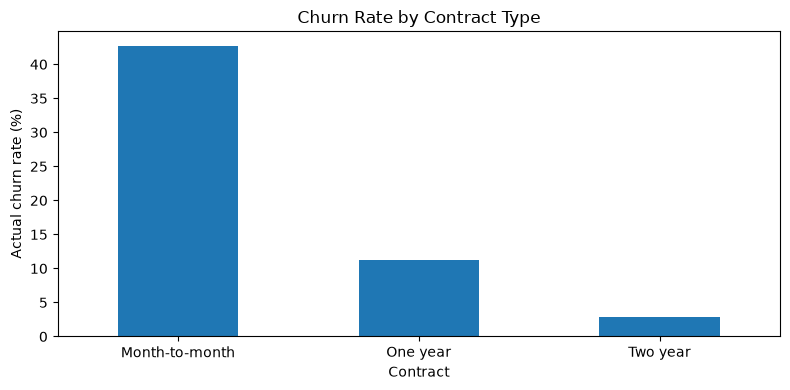

In [7]:
contract_summary = (
    df.groupby("Contract", observed=True)
    .agg(
        Customers=("customerID", "count"),
        Actual_Churn_Rate=(
            "Churn",
            lambda s: s.eq("Yes").mean() * 100
        )
    )
    .sort_values("Actual_Churn_Rate", ascending=False)
)

display(contract_summary.round(2))

contract_summary["Actual_Churn_Rate"].plot(
    kind="bar",
    figsize=(8, 4),
    ylabel="Actual churn rate (%)",
    title="Churn Rate by Contract Type",
    rot=0
)

plt.tight_layout()
plt.show()

#### Create a risk-segment chart

,Customers
Risk_Segment,
Low,5060
Medium,1453
High,530


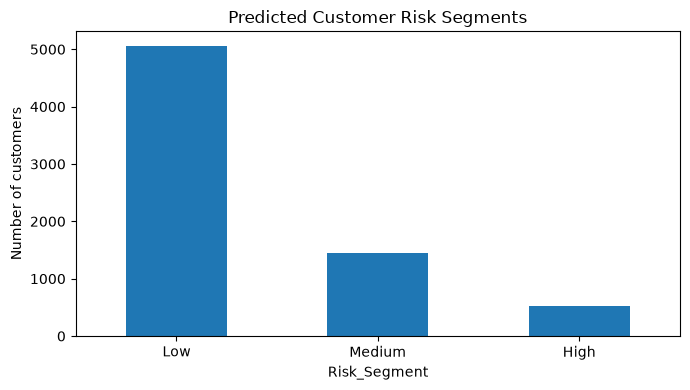

In [8]:
risk_counts = df["Risk_Segment"].value_counts().reindex(
    ["Low", "Medium", "High"], fill_value=0
)

display(risk_counts.rename("Customers").to_frame())

risk_counts.plot(
    kind="bar",
    figsize=(7, 4),
    ylabel="Number of customers",
    title="Predicted Customer Risk Segments",
    rot=0
)

plt.tight_layout()
plt.show()

#### Export the dashboard data

In [9]:
Path("reports").mkdir(exist_ok=True)

df.to_csv(
    "reports/dashboard_customer_data.csv",
    index=False
)

contract_summary.to_csv(
    "reports/dashboard_contract_summary.csv"
)

risk_counts.to_csv(
    "reports/dashboard_risk_summary.csv"
)

print("Dashboard datasets exported to the reports folder.")

Dashboard datasets exported to the reports folder.


#### Create the interactive Streamlit dashboard

In [10]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

st.set_page_config(
    page_title="Customer Intelligence",
    page_icon="📊",
    layout="wide"
)

st.title("Customer Intelligence & Churn Dashboard")
st.caption("Churn analytics, predictive risk, and retention insights")

DATA_PATH = Path("data/raw/Telco-Customer-Churn.csv")
MODEL_PATH = Path("models/customer_churn_optimized_pipeline.joblib")
CONFIG_PATH = Path("models/customer_churn_config.joblib")

if not DATA_PATH.exists() or not MODEL_PATH.exists():
    st.error("Dataset or saved model not found. Check your project folders.")
    st.stop()

@st.cache_data
def load_data(path):
    return pd.read_csv(path)

@st.cache_resource
def load_model(path):
    return joblib.load(path)

df = load_data(str(DATA_PATH))
model = load_model(str(MODEL_PATH))

config = joblib.load(CONFIG_PATH) if CONFIG_PATH.exists() else {}
threshold = float(config.get("best_threshold", 0.5))

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)
df.loc[
    df["TotalCharges"].isna() & (df["tenure"] == 0),
    "TotalCharges"
] = 0

df = df.drop_duplicates(subset=["customerID"]).copy()

feature_columns = list(
    model.named_steps["preprocessor"].feature_names_in_
)
X = df.drop(
    columns=["Churn", "customerID"], errors="ignore"
)[feature_columns]

df["Churn_Probability"] = model.predict_proba(X)[:, 1]
df["Predicted_Churn"] = (
    df["Churn_Probability"] >= threshold
).astype(int)

df["Risk_Segment"] = pd.cut(
    df["Churn_Probability"],
    bins=[-np.inf, 0.40, 0.70, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

total = len(df)
actual_rate = (
    df["Churn"].eq("Yes").mean() * 100
    if "Churn" in df.columns else 0
)
predicted_rate = df["Predicted_Churn"].mean() * 100
high_risk = int(df["Risk_Segment"].eq("High").sum())

c1, c2, c3, c4 = st.columns(4)
c1.metric("Total Customers", f"{total:,}")
c2.metric("Actual Churn Rate", f"{actual_rate:.2f}%")
c3.metric("Predicted Churn Rate", f"{predicted_rate:.2f}%")
c4.metric("High-Risk Customers", f"{high_risk:,}")

st.subheader("Churn by Contract Type")
contract_summary = (
    df.groupby("Contract", observed=True)
    .agg(
        Customers=("customerID", "count"),
        Churn_Rate=(
            "Churn",
            lambda s: s.eq("Yes").mean() * 100
        )
    )
    .sort_values("Churn_Rate", ascending=False)
)
st.bar_chart(contract_summary["Churn_Rate"])
st.dataframe(contract_summary.round(2), use_container_width=True)

st.subheader("Predicted Risk Segments")
risk_summary = (
    df.groupby("Risk_Segment", observed=False)
    .agg(
        Customers=("customerID", "count"),
        Average_Churn_Probability=("Churn_Probability", "mean"),
        Average_Monthly_Charges=("MonthlyCharges", "mean")
    )
)
st.dataframe(risk_summary.round(3), use_container_width=True)

st.subheader("Find Customers by Risk")
selected_risk = st.selectbox(
    "Select risk segment",
    ["All", "High", "Medium", "Low"]
)

filtered = df.copy()
if selected_risk != "All":
    filtered = filtered[
        filtered["Risk_Segment"].astype(str) == selected_risk
    ]

display_columns = [
    "customerID", "Contract", "tenure", "MonthlyCharges",
    "Churn_Probability", "Predicted_Churn", "Risk_Segment"
]
st.dataframe(
    filtered[display_columns].sort_values(
        "Churn_Probability", ascending=False
    ),
    use_container_width=True
)

csv = filtered.to_csv(index=False).encode("utf-8")
st.download_button(
    "Download filtered customer data",
    data=csv,
    file_name="customer_churn_dashboard.csv",
    mime="text/csv"
)

st.info(
    "Risk bands are business-defined. Model probabilities are estimates, "
    "and retention actions should be tested against real outcomes."
)


Overwriting app.py


In [11]:
import os

print("Current folder:", os.getcwd())
print("app.py exists:", os.path.exists("app.py"))

Current folder: C:\Users\vikra\Desktop\Project
app.py exists: True


In [12]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [ ]:
!streamlit run app.py